# Evaluate

So sánh đúng bốn phương pháp. Cân bằng coverage là policy, không phải một phương pháp bổ sung.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project_directory = next(path for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                         if (path / "recommendation/config.json").is_file())
sys.path.insert(0, str(project_directory / "recommendation/src"))
from pipeline_common import ROOT, ARTIFACTS, REPORTS, read_json, load_csv


In [2]:
from evaluate import evaluate_snapshot, audit_results, paired_uncertainty
cohort_metrics = evaluate_snapshot()
primary_metrics = load_csv(REPORTS / "test_primary_primary.csv")
display(primary_metrics)


,model,precision_at_10,recall_at_10,f1_at_10,ndcg_at_10,coverage,concentration,observed_auc
0,CollaborativeFiltering,0.165129,0.394763,0.214866,0.272634,0.916042,0.489190,0.498352
1,ContentBased,0.158220,0.383837,0.206667,0.272911,0.947753,0.263095,0.514857
2,Hybrid,0.168190,0.396629,0.217720,0.276428,0.930209,0.417905,0.498129
3,Popularity,0.166448,0.398361,0.216998,0.288740,0.922273,0.439667,0.478351


## Trực quan và đánh đổi

So với xếp hạng gốc để thấy policy ảnh hưởng chất lượng và coverage ra sao. Các phương pháp dùng cùng nguồn và ứng viên.

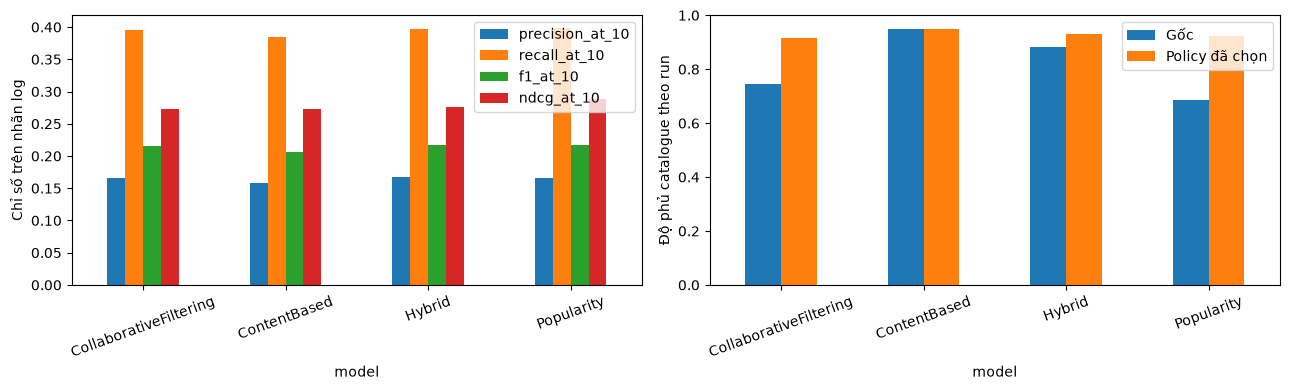

In [3]:
figure, axes = plt.subplots(1,2,figsize=(13,4))
primary_metrics.set_index("model")[["precision_at_10","recall_at_10","f1_at_10","ndcg_at_10"]].plot.bar(ax=axes[0],rot=20)
axes[0].set_ylabel("Chỉ số trên nhãn log")
raw_metrics = load_csv(REPORTS / "test_primary_primary_raw.csv").set_index("model")
pd.DataFrame({"Gốc":raw_metrics.coverage,"Policy đã chọn":primary_metrics.set_index("model").coverage}).plot.bar(ax=axes[1],rot=20)
axes[1].set_ylim(0,1)
axes[1].set_ylabel("Độ phủ catalogue theo run")
figure.tight_layout()
plt.show()


In [4]:
display(load_csv(REPORTS / "test_primary_primary_raw.csv"))
display(load_csv(REPORTS / "test_historical_primary.csv"))
display(cohort_metrics.loc[cohort_metrics["mode"].eq("raw") & cohort_metrics.model.eq("Popularity"),["cohort","eligible_users","evaluated_users","users_without_positives","candidate_count","test_positive_count","oracle_precision_at_10","oracle_recall_at_10"]])


,model,precision_at_10,recall_at_10,f1_at_10,ndcg_at_10,coverage,concentration,observed_auc
0,CollaborativeFiltering,0.164038,0.389715,0.213097,0.270751,0.744334,0.490857,0.498352
1,ContentBased,0.158220,0.383837,0.206667,0.272911,0.947753,0.263095,0.514857
2,Hybrid,0.167832,0.396031,0.217272,0.276115,0.882783,0.418571,0.498129
3,Popularity,0.166810,0.397956,0.217371,0.288656,0.685717,0.439667,0.478351


,model,precision_at_10,recall_at_10,f1_at_10,ndcg_at_10,coverage,concentration,observed_auc
0,CollaborativeFiltering,0.033943,0.060951,0.039349,0.060570,0.556008,0.747910,0.541783
1,ContentBased,0.013838,0.023832,0.015798,0.017512,0.932790,0.129718,0.453396
2,Hybrid,0.027154,0.046431,0.031461,0.043132,0.900204,0.346554,0.521226
3,Popularity,0.059008,0.115401,0.070579,0.106573,0.900204,0.766328,0.524024


,cohort,eligible_users,evaluated_users,users_without_positives,candidate_count,test_positive_count,oracle_precision_at_10,oracle_recall_at_10
0,historical_assumed_single,885,383,502,466.201044,5.493473,0.510966,0.973164
8,run=2ad86635f1a18e06,100,92,8,36.913043,4.586957,0.428261,0.979573
16,run=94f1d592a7787780,70,63,7,16.380952,4.047619,0.401587,0.997354
24,run=e1d06d3cf6587c44,100,93,7,56.473118,5.698925,0.536559,0.975673


## Kiểm chứng và đối chứng

Audit tính lại metric từ ID và positive test. Khoảng tin cậy có điều kiện trên ba run và model đã fit; không bảo đảm tổng quát ra người thật.

In [5]:
display(pd.Series(audit_results()))
display(paired_uncertainty())
for scenario in ["historical_day","engagement","permuted"]:
    path = REPORTS / f"test_primary_{scenario}.csv"
    if path.exists():
        print(scenario)
        display(load_csv(path))


status                                                                                   PASS
methods                                     [Popularity, ContentBased, CollaborativeFilter...
checked_lists                                                                            9240
metric_maximum_absolute_error                                                             0.0
factor_gradient_error                                                                     0.0
sources_and_collaborator_unchanged                                                       True
proves_absence_of_all_leakage_or_overfit                                                False
old_test_previously_inspected                                                            True
dtype: object

,mode,model,baseline,metric,mean_difference,simultaneous_ci_lower,simultaneous_ci_upper
0,raw,ContentBased,Popularity,precision_at_10,-0.008590,-0.031958,0.013129
1,raw,ContentBased,Popularity,recall_at_10,-0.014119,-0.083861,0.051978
2,raw,ContentBased,Popularity,f1_at_10,-0.010704,-0.038565,0.020600
3,raw,ContentBased,Popularity,ndcg_at_10,-0.015745,-0.068833,0.039017
4,raw,CollaborativeFiltering,Popularity,precision_at_10,-0.002772,-0.022523,0.017777
5,raw,CollaborativeFiltering,Popularity,recall_at_10,-0.008242,-0.061539,0.040816
6,raw,CollaborativeFiltering,Popularity,f1_at_10,-0.004274,-0.029491,0.021351
7,raw,CollaborativeFiltering,Popularity,ndcg_at_10,-0.017905,-0.060573,0.021165
8,raw,Hybrid,Popularity,precision_at_10,0.001022,-0.020140,0.022839
9,raw,Hybrid,Popularity,recall_at_10,-0.001925,-0.054428,0.049487


historical_day


,model,precision_at_10,recall_at_10,f1_at_10,ndcg_at_10,coverage,concentration,observed_auc
0,CollaborativeFiltering,0.165129,0.394763,0.214866,0.272634,0.916042,0.489190,0.498352
1,ContentBased,0.158220,0.383837,0.206667,0.272911,0.947753,0.263095,0.514857
2,Hybrid,0.168190,0.396629,0.217720,0.276428,0.930209,0.417905,0.498129
3,Popularity,0.166448,0.398361,0.216998,0.288740,0.922273,0.439667,0.478351


engagement


,model,precision_at_10,recall_at_10,f1_at_10,ndcg_at_10,coverage,concentration,observed_auc
0,CollaborativeFiltering,0.115163,0.424783,0.169661,0.248731,0.900466,0.470571,0.507402
1,ContentBased,0.105715,0.382937,0.156216,0.225108,0.970831,0.246952,0.512107
2,Hybrid,0.109517,0.393891,0.160103,0.229754,0.922273,0.424000,0.504113
3,Popularity,0.105195,0.388418,0.154062,0.253845,0.922273,0.453286,0.481892


permuted


,model,precision_at_10,recall_at_10,f1_at_10,ndcg_at_10,coverage,concentration,observed_auc
0,CollaborativeFiltering,0.162928,0.392612,0.212501,0.266247,0.917748,0.460476,0.513753
1,ContentBased,0.162564,0.403435,0.213909,0.269767,0.962755,0.264190,0.483087
2,Hybrid,0.161879,0.392296,0.211753,0.270473,0.930209,0.410429,0.499587
3,Popularity,0.169616,0.401916,0.220629,0.289155,0.911518,0.440238,0.475612
